Sampling: [n_det, n_e]


Среднее = 124.044
Std  = 13.613867980900997


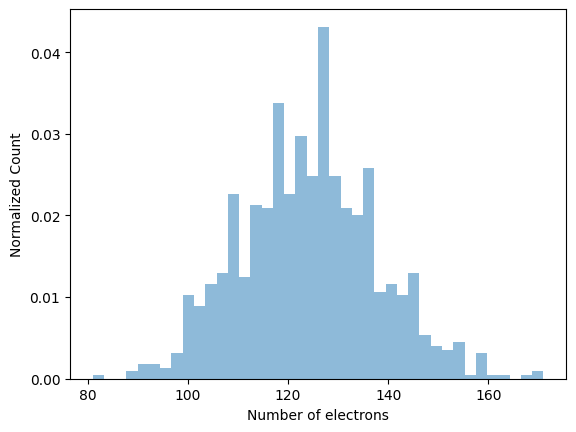

In [2]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx=" #-- не запускалось без этой правки 

import pymc as pm
import pytensor.tensor as pt
import numpy as np
import matplotlib.pyplot as plt

m,cm=1,0.01
origin=np.array([0,0,0])

EventCount=1000
E = 1
R=2*m
N=40
r=10*cm
prob=0.5
def DetectorResponse(E: float,origin:np.ndarray):
    Y=10**4
    N_ph = int(E * Y)
    p_hit = N * r**2 / (4 * R**2) # т.к ФЭУ расположены равномерно
    with pm.Model() as model:
        n_det=pm.Binomial("n_det",n=N_ph, p= p_hit)
        n_e = pm.Poisson("n_e",mu=prob * n_det)
    return model

model = DetectorResponse(E,origin)
with model:
    data = pm.sample_prior_predictive(EventCount)

n_e = np.asarray(data.prior["n_e"]).ravel()
print("Среднее =", n_e.mean())
print("Std  =", n_e.std(ddof=1))
plt.hist(n_e, bins=40, density=True, alpha=0.5)
plt.xlabel("Number of electrons")
plt.ylabel("Normalized Count")
plt.show()

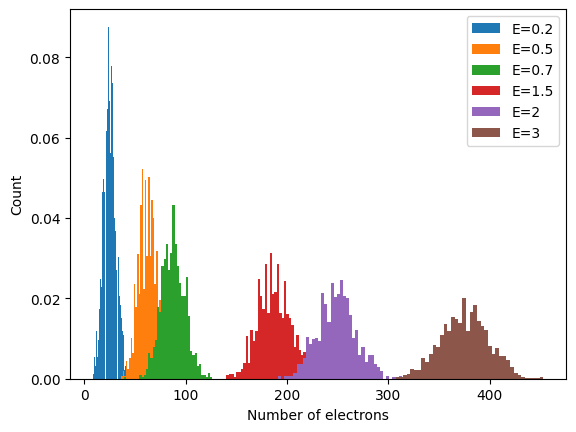

In [14]:
#для сравнения с заданием 4 
m,cm=1,0.01
class Detector():
    def __init__(self, R=2*m,N=40,r=10*cm, prob=0.5):
        self.R=R
        self.N=N
        self.r=r
        self.prob=prob
        self.PMTArray=self.uniform_distribution()
    def uniform_distribution(self):
        i = np.arange(self.N)
        golden_ratio = (1 + np.sqrt(5)) / 2
        cosTheta = 1 - 2 * (i + 0.5) / self.N
        sinTheta = np.sqrt(1 - cosTheta*cosTheta)
        phi = 2 * np.pi * i / golden_ratio
        return self.R * np.array([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta])
        
    def IsInPMT(self,origin:np.ndarray,PhotonArray:np.ndarray):
        cosMax=np.cos(self.r/self.R)
        cosCheck=(origin[:, None]+PhotonArray).T@ self.PMTArray/ (self.R ** 2)
        return np.any(cosCheck>cosMax, axis=1)
        
    def ElectronYield(self, NDetected:float):
        return np.random.poisson(self.prob * NDetected) #по свойству распределения пуассона 



class Source():
    def __init__(self, E:float,origin:np.ndarray,Y=1e4):
        self.Y=Y
        self.N=int(E*Y)
        self.origin=origin
        self.PhotonArray=self.random_distribution()
    def random_distribution(self):
        phi=np.random.uniform(0,2*np.pi, self.N)
        cosTheta=np.random.uniform(-1,1,self.N)
        sinTheta=np.sqrt(1-cosTheta*cosTheta)
        return np.array([sinTheta*np.cos(phi),sinTheta*np.sin(phi), cosTheta])
    def distance_traversed(self,R:float):
        t=-self.origin@self.PhotonArray+np.sqrt(R**2-np.sum(self.origin**2)+(self.origin@self.PhotonArray)*(self.origin@self.PhotonArray))
        return t

 
D1=Detector()
origin=np.array([0,0,0])

EventCount=1000
def Event(E:float, EventCount:int, origin:np.array):
    N_e = []
    #все фотоны долетают до ФЭУ
    for i in range(EventCount):
        S1=Source(E,origin)
        registered=np.sum(D1.IsInPMT(origin,S1.PhotonArray*S1.distance_traversed(D1.R)))
        N_e.append(D1.ElectronYield(registered))
    return np.array(N_e)            

def plotter(N_e:np.array):
    for i in range(len(Elist)):
        plt.hist(N_e[i], bins=40,density=True, label=f"E={Elist[i]}")
    plt.legend()
    plt.xlabel("Number of electrons")
    plt.ylabel("Count")
    plt.show()
        
Elist=[0.2,0.5,0.7,1.5,2,3]
N_e = np.array([Event(E, EventCount,origin) for E in Elist])

plotter(N_e)

Sampling: [n_det, n_e]


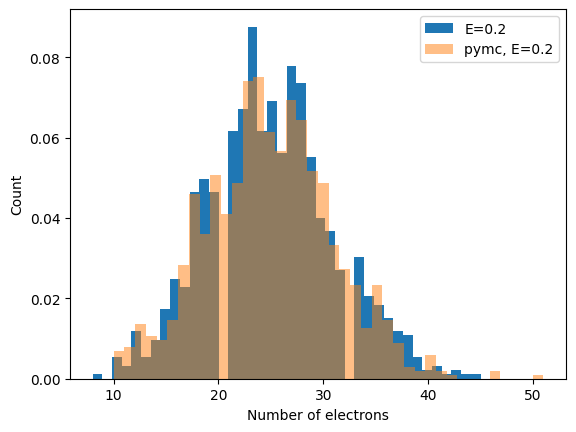

Sampling: [n_det, n_e]


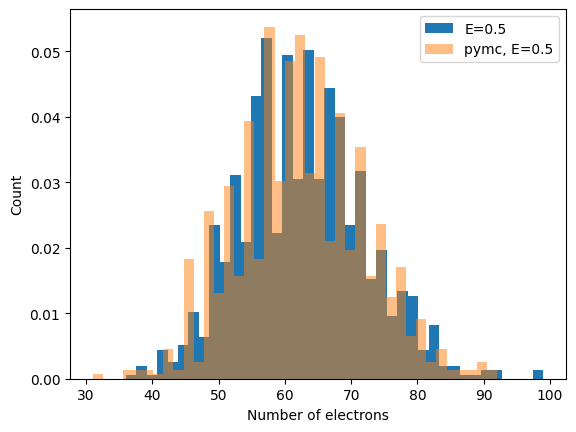

Sampling: [n_det, n_e]


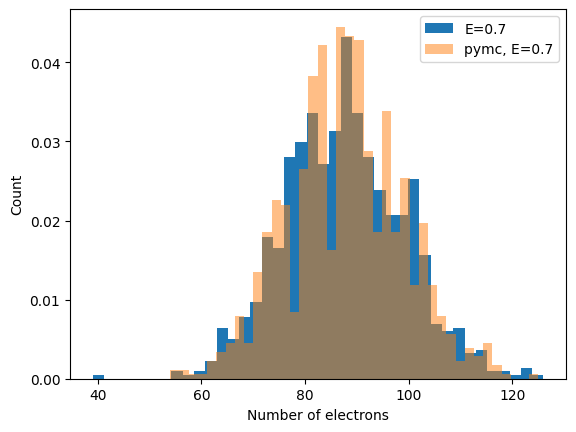

Sampling: [n_det, n_e]


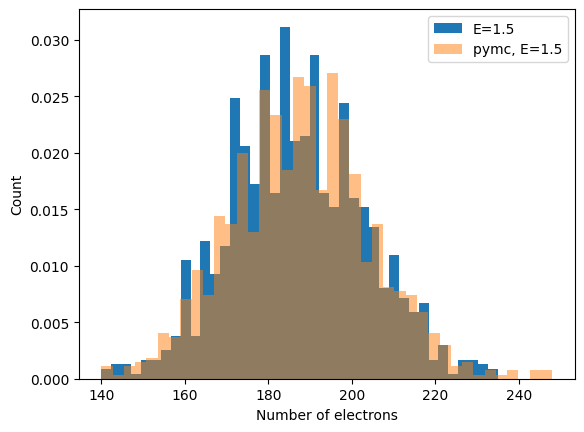

Sampling: [n_det, n_e]


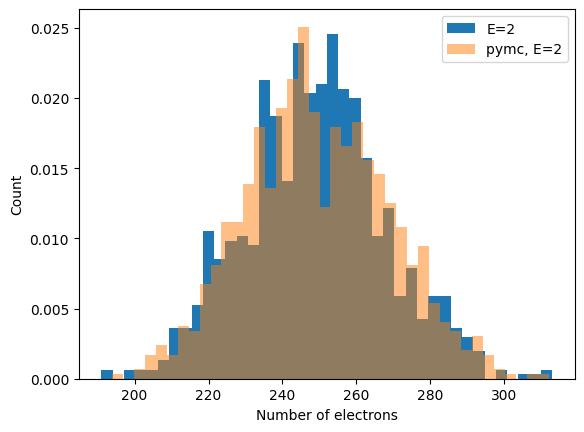

Sampling: [n_det, n_e]


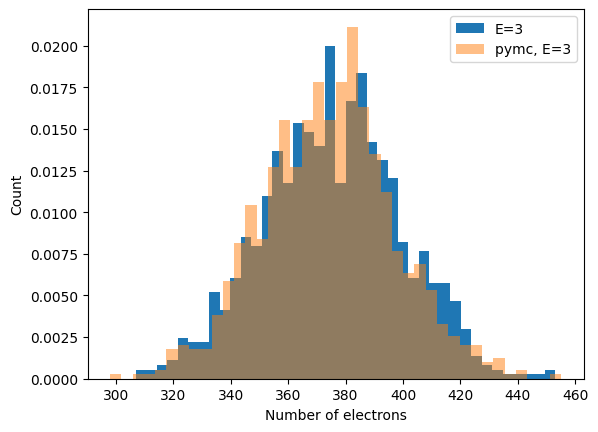

In [15]:
#Сравнение распределений полученных в pymc и предыдущим способом
for i in range(len(Elist)):
    plt.hist(N_e[i], bins=40,density=True, label=f"E={Elist[i]}")
    model = DetectorResponse(Elist[i],origin)
    with model:
        data = pm.sample_prior_predictive(EventCount)
    n_e = np.asarray(data.prior["n_e"]).ravel()
    plt.hist(n_e, bins=40, density=True, alpha=0.5, label=f"pymc, E={Elist[i]}")
    plt.legend()
    plt.xlabel("Number of electrons")
    plt.ylabel("Count")
    plt.show()